In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math
import seaborn as sns
import scipy
from scipy.integrate import quad
plt.rcParams['figure.figsize'] = [11, 7]

## Standard medium

#### Experimental average growth rate

In [2]:
growth_file = 'experiments/new_data/growth_data.dat'
data_g = pd.read_csv(growth_file, sep='\t')
 
data_g = data_g.iloc[0:-2]
data_g

,Timepoint,hours after innoculatio,duplicate,OD730 (24h vial),dilution factor,cells/ml (24h vial),OD730 (SIMS sample),cells/ml (sample)
0,0,0,1,0.0441,5,11025000,0.0000,0
1,0,0,2,0.0502,5,12550000,0.0000,0
2,1,4,1,0.0473,5,11825000,0.2158,10790000
3,1,4,2,0.0535,5,13375000,0.2287,11435000
4,2,6,1,0.0613,5,15325000,0.2361,11805000
5,2,6,2,0.0699,5,17475000,0.2443,12215000
6,3,12,1,0.0826,5,20650000,0.3595,17975000
7,3,12,2,0.0755,5,18875000,0.3147,15735000
8,4,13,1,0.0523,5,13075000,0.2504,12520000
9,4,13,2,0.0571,5,14275000,0.2550,12750000


In [3]:
times = list(np.unique(data_g['hours after innoculatio']))

cells_24_1 = list(data_g[data_g['duplicate']==1]['cells/ml (24h vial)'])
cells_24_2 = list(data_g[data_g['duplicate']==2]['cells/ml (24h vial)'])
cells_SIMS_1 = list(data_g[data_g['duplicate']==1]['cells/ml (sample)'])
cells_SIMS_2 = list(data_g[data_g['duplicate']==2]['cells/ml (sample)'])

avgs = [np.mean([cells_24_1[0], cells_24_2[0]])]
sds =  [np.std([cells_24_1[0], cells_24_2[0]])]

for i in range(1,len(cells_24_1)):
    avgs.append(np.mean([cells_24_1[i], cells_24_2[i], cells_SIMS_1[i], cells_SIMS_2[i]]))
    sds.append(np.std([cells_24_1[i], cells_24_2[i], cells_SIMS_1[i], cells_SIMS_2[i]]))

In [4]:
g_1_4h = (np.log(cells_24_1[1])-np.log(cells_24_1[0])) / (times[1]-times[0])
g_2_4h = (np.log(cells_24_2[1])-np.log(cells_24_2[0])) / (times[1]-times[0])
print(np.mean([g_1_4h, g_2_4h]), np.std([g_1_4h, g_2_4h]))
growth_rate_exp = np.mean([g_1_4h, g_2_4h])
std_var_exp = np.std([g_1_4h, g_2_4h])

0.016714642531170387 0.0007979857301010362


In [5]:
g_1_12h = (np.log(cells_24_1[3])-np.log(cells_24_1[0])) / (times[3]-times[0])
g_2_12h = (np.log(cells_24_2[3])-np.log(cells_24_2[0])) / (times[3]-times[0])
print(np.mean([g_1_12h, g_2_12h]), np.std([g_1_12h, g_2_12h]))
growth_rate_exp = np.mean([g_1_12h, g_2_12h])
std_var_exp = np.std([g_1_12h, g_2_12h])

0.043152813651309366 0.009143011188201672


In [6]:
#g_1_4h = (np.log(cells_24_1[3])-np.log(cells_24_1[0])) / (times[3]-times[0])
#g_2_4h = (np.log(cells_24_2[3])-np.log(cells_24_2[0])) / (times[3]-times[0])
#print(np.mean([g_1_4h, g_2_4h]), np.std([g_1_4h, g_2_4h]))
#growth_rate_exp = np.mean([g_1_4h, g_2_4h])
#std_var_exp = np.std([g_1_4h, g_2_4h])

#### Estimating maximum growth rate and transforming replacement rates to uptake rates

## 12h - replicate 2

In [9]:
plt.rcParams['figure.figsize'] = [7, 4]

C_carbon = 41.07
rates_C = 'results_new/peak_movement_rates_4to12h_C_NEW.dat'
rates_N = 'results_new/peak_movement_rates_4to12h_N_NEW.dat'
C_nitrogen = 8.23


replacement_r_C = pd.read_csv(rates_C, sep = ',')
replacement_r_N = pd.read_csv(rates_N, sep = ',')

C_rates = [i if i>0 else 0.00001 for i in replacement_r_C['C_rates']]
N_rates = [i for i in replacement_r_N['N_rates']]

max_growths = []
C_uptake = []
N_uptake = []
for i in range(0,len(C_rates)):
    l = min(C_rates[i], N_rates[i])
    max_growths.append(l)
    C_uptake.append(C_rates[i]*C_carbon)
    N_uptake.append(N_rates[i]*C_nitrogen)

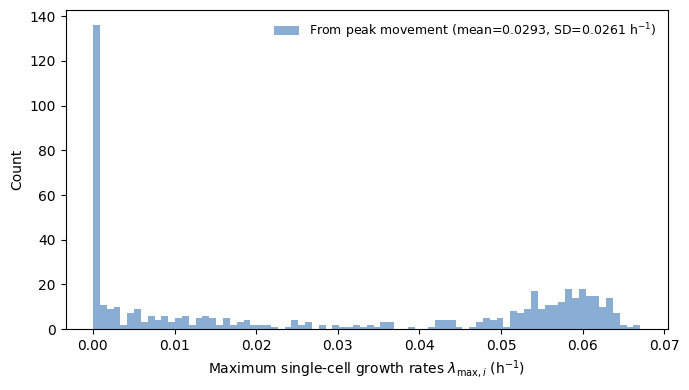

From peak motion: mean = 0.02926 h^-1, SD = 0.02607 h^-1


In [16]:
import numpy as np
import matplotlib.pyplot as plt

colors = {"previous": "#c05621", "peak": "#2b6cb0"}

mean_peak, sd_peak = np.mean(max_growths), np.std(max_growths, ddof=1)

fig, ax = plt.subplots(figsize=(7, 4))

ax.hist(
    max_growths, bins=80, color=colors["peak"], alpha=0.55,
    label=f"From peak movement (mean={mean_prev:.4f}, SD={sd_prev:.4f} h$^{{-1}}$)", log=False
)

ax.set_xlabel(r"Maximum single-cell growth rates $\lambda_{\max,i}$ (h$^{-1}$)")
ax.set_ylabel("Count")
#ax.set_title("Distribution of maximum growth rates")
ax.legend(frameon=False, fontsize=9)

plt.tight_layout()
plt.savefig("max_growth_hist.png", dpi=200, bbox_inches="tight")
plt.show()

print(f"From peak motion: mean = {mean_peak:.5f} h^-1, SD = {sd_peak:.5f} h^-1")

In [10]:
pd.DataFrame(max_growths).to_csv('results_new/max_growths_std_12h_PEAKS.dat', sep='\t', index=False, header=False)

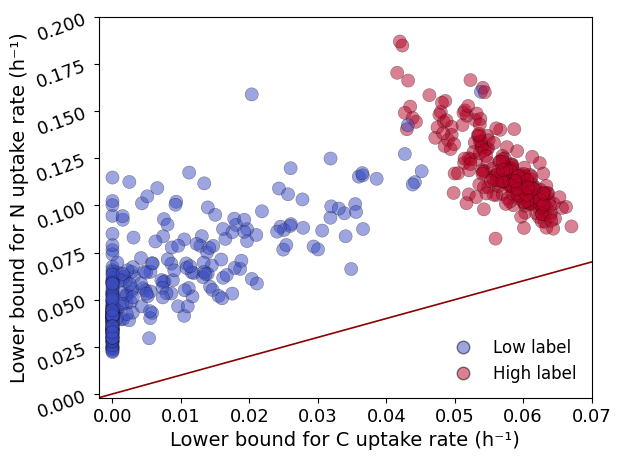

In [17]:

darkblue_transparent = (0.0, 0.0, 0.55, 0.3)     # darkblue with alpha
darkorange_transparent = (1.0, 0.55, 0.0, 0.4)   # darkorange with alpha

color12 = (0.0, 0.5, 0.5, 0.35)     # teal (fill)
color4 = (0.8, 0.4, 0.6, 0.4)     # soft magenta (fill)

rates_C = 'peak_movement_rates_4to12h_C_NEW.dat'
rates_N = 'peak_movement_rates_4to12h_N_NEW.dat'
replacement_r_C = pd.read_csv(rates_C, sep = ',')
replacement_r_N = pd.read_csv(rates_N, sep = ',')

clusters = 'results_new/clusters_4to12h_N_NEW.dat'
clusters = pd.read_csv(clusters)

C_rates = [i if i>0 else 0.00001 for i in replacement_r_C['C_rates']]
N_rates = [i for i in replacement_r_N['N_rates']]

plt.rcParams['figure.figsize'] = [9/1.415, 7/1.415]

from matplotlib.lines import Line2D

plt.scatter(C_rates, N_rates, c=clusters['cluster'], marker='o', s=90,
            edgecolors='black', cmap='coolwarm', alpha=0.5, linewidths=0.3)
# facecolors=color12 removed -- it's silently ignored whenever c= is passed

cmap = plt.cm.coolwarm
legend_elements = [
    Line2D([0], [0], marker='o', color='w', label='Low label',
           markerfacecolor=cmap(0.0), markeredgecolor='black', markersize=9, alpha=0.5),
    Line2D([0], [0], marker='o', color='w', label='High label',
           markerfacecolor=cmap(1.0), markeredgecolor='black', markersize=9, alpha=0.5),
]
plt.legend(handles=legend_elements, fontsize=12, loc='lower right', frameon=False)

plt.xlabel('Lower bound for C uptake rate (h⁻¹)', fontsize=14)
plt.ylabel('Lower bound for N uptake rate (h⁻¹)', fontsize=14)
#plt.legend(fontsize=15, markerscale = 1.3, loc='lower right')
plt.yticks(fontsize=13, rotation=20)
plt.xticks(fontsize=13)

x = np.linspace(-0.01, 0.28, 1000)
plt.plot(x,x, linewidth= 1.2, color = 'darkred')
plt.xlim(-0.002,0.07)
plt.ylim(-0.002, 0.2)
plt.savefig('r_rates.jpeg', format='jpeg', dpi=200, bbox_inches='tight')
#plt.savefig('../../drafts/synecho/def_figures/r_rates.svg', format='svg', dpi=2000)
#plt.savefig('../../drafts/synecho/def_figures/r_rates.eps', format='eps')
plt.show()

In [18]:

clusters = 'results_new/clusters_4to12h_N_NEW.dat'
clusters = pd.read_csv(clusters)
clusters

,cluster
0,1
1,1
2,0
3,0
4,0
...,...
515,0
516,0
517,1
518,0


#### Correcting average growth rate for truncated distribution

In [21]:
max_lambda = np.mean(max_growths)
max_lambda = 0.035

growth_rate_exp = 0.04
std_var_exp = 0.002

f1 = lambda x: x * math.exp(-(x - growth_rate_exp)**2/(2*std_var_exp**2))
f2 = lambda x: math.exp(-(x - growth_rate_exp)**2/(2*std_var_exp**2))

num = quad(np.vectorize(f1), 0, max_lambda)
den = quad(np.vectorize(f2), 0, max_lambda)

avg_growth_exp = round(num[0]/den[0], 4)
#avg_growth_exp = 0.036
avg_growth_exp

0.0344

#### Maximum entropy to estimate growth rates
Calculating beta:

Beta:  10.501210024200489


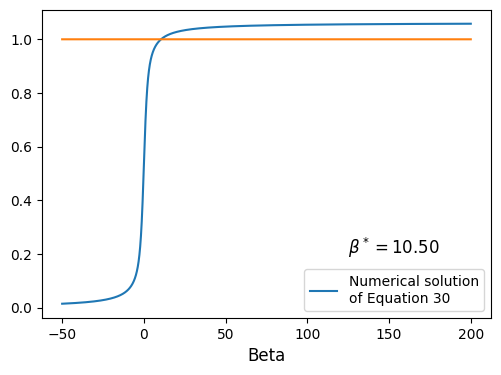

In [22]:


## USING BULK GROWTH RATE
avg_growth_exp = 0.0344

t_b = np.log(2)/avg_growth_exp


plt.rcParams['figure.figsize'] = [5.8, 4]

x = np.linspace(-50, 200,50000)
#x = np.linspace(-5, 5, 20000)

max_y = [math.e**(g*t_b)-1 for g in max_growths]

#beta_solution = -100
diff = 1000000000
f_values = []
for beta in x:
    summ = 0
    summ_y = 0
    for y in max_y:
        #print(g)
        summ += y * ( 1 / ( 1 - np.exp( - beta * y ) ) )
        summ_y += y
    f = summ / len(max_y) - 1 / beta
    f_values.append(f)
    if abs(1-f) < diff:
        diff = abs(1-f)
        beta_solution = beta
beta = beta_solution
print('Beta: ', beta)


#plt.plot([beta]*len(x), np.linspace(0,0.012,len(x)), linestyle='dashed', label='', color='black')
plt.plot(x, f_values, label='Numerical solution\nof Equation 30')
plt.plot(x, [1]*len(x))
plt.xlabel('Beta', fontsize=12)
plt.text(125, 0.2,  rf'$\beta^* = {beta:.2f}$', fontsize=12)
#plt.ylabel('Average growth rate (h⁻¹)', fontsize=12)
fig_name = 'beta.jpeg'
plt.legend()
plt.savefig(fig_name, dpi=200)
#plt.text(1600, 0.0002, 'Beta = 1272.31')
#plt.ylim(0,0.012)
plt.show()




In [27]:
condition = 'std'


from scipy.stats import truncnorm
avg_cell = []
std_cell = []
t_b = np.log(2) / 0.035
for y in max_y:
    y_cell = beta/(math.e**(beta*y)-1)*((y*beta-1)/(beta*beta)*math.e**(beta*y)+1/(beta*beta))
    s_cell = beta/(math.e**(beta*y)-1)*(math.e**(beta*y)*((y*y)*(beta*beta)-2*(y*beta-1))/beta**3-2/beta**3)
    sd_cell = (s_cell-y_cell**2)**(1/2)
    sd_cell = 1/(t_b*(y_cell+1))*sd_cell
    g_cell = np.log(y_cell+1)/t_b
    
    avg_cell.append(g_cell)

    std_cell.append(sd_cell)
    
results_std_1 = pd.DataFrame([C_rates,N_rates,C_uptake, N_uptake, avg_cell, std_cell],
                        index = ['r_C', 'r_N', 'u_C', 'u_N', 'g', 'sd']).transpose()

#results_file_name = 'results_new/results_'+condition+'_corrected_12h_perturbed.dat'
#results_file_name = 'results_new/results_'+condition+'_corrected_12h_PEAKS.dat'

#results_std_1.to_csv(results_file_name, sep='\t', index=False)

results_std_1



,r_C,r_N,u_C,u_N,g,sd
0,0.061354,0.100474,2.519806,0.826900,0.061008,0.001436
1,0.057014,0.112534,2.341554,0.926153,0.056460,0.001572
2,0.011694,0.051683,0.480267,0.425351,0.008693,0.002737
3,0.014260,0.056870,0.585652,0.468042,0.011189,0.002999
4,0.014630,0.055157,0.600838,0.453945,0.011559,0.003025
...,...,...,...,...,...,...
515,0.005781,0.069327,0.237443,0.570559,0.003641,0.001608
516,0.000010,0.032722,0.000411,0.269305,0.000005,0.000003
517,0.054587,0.126257,2.241893,1.039095,0.053913,0.001653
518,0.000010,0.044336,0.000411,0.364886,0.000005,0.000003


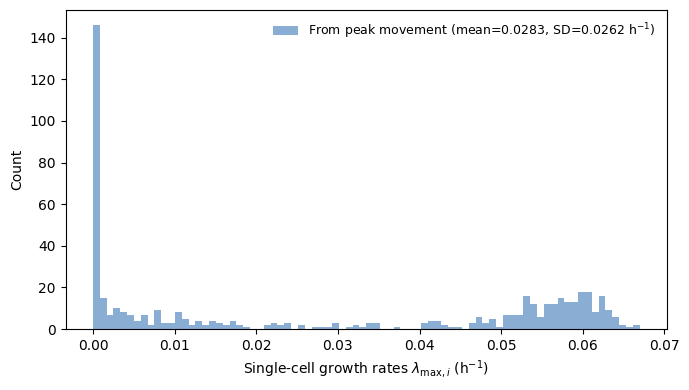

In [30]:
colors = {"previous": "#c05621", "peak": "#2b6cb0"}


mean_prev, sd_prev = np.mean(results_std_1['g']), np.std(results_std_1['g'], ddof=1)

fig, ax = plt.subplots(figsize=(7, 4))

ax.hist(
    results_std_1['g'], bins=80, color=colors["peak"], alpha=0.55,
    label=f"From peak movement (mean={mean_prev:.4f}, SD={sd_prev:.4f} h$^{{-1}}$)", log=False
)


ax.set_xlabel(r"Single-cell growth rates $\lambda_{\max,i}$ (h$^{-1}$)")
ax.set_ylabel("Count")
#ax.set_title("Distribution of maximum growth rates")
ax.legend(frameon=False, fontsize=9)

plt.tight_layout()
#plt.savefig("growth_hist.png", dpi=200, bbox_inches="tight")
#
#plt.show()

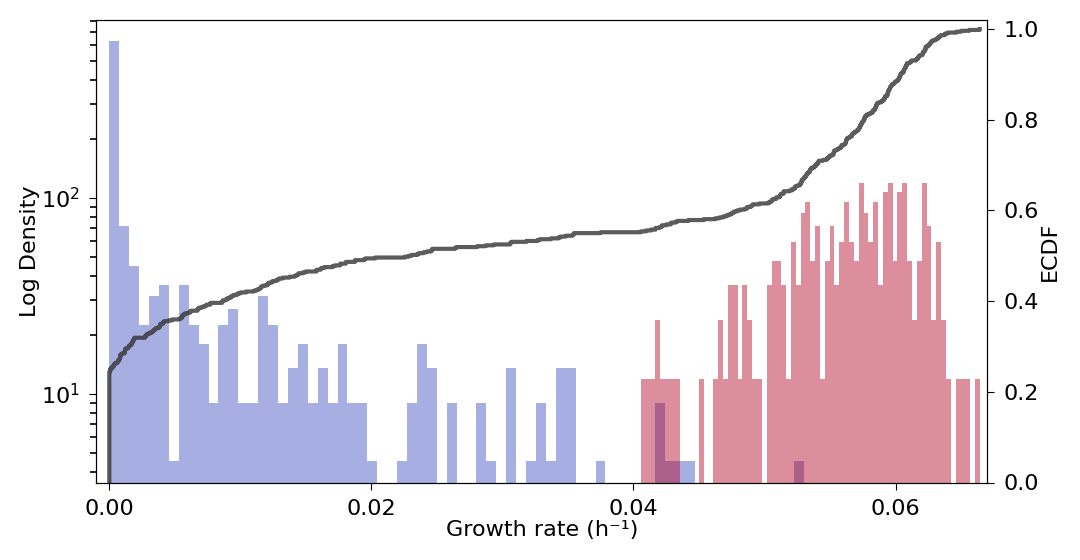

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

df2 = pd.read_csv('results_new/results_std_corrected_12h_PEAKS.dat', sep='\t')
clusters = pd.read_csv('results_new/clusters_4to12h_N_NEW.dat', sep='\t')

# same coolwarm extremes used in your C/N-rate scatter legend
cmap = plt.cm.coolwarm
color_peak1 = cmap(0.0)[:3] + (0.45,)   # coolwarm dark blue -> Peak 1
color_peak2 = cmap(1.0)[:3] + (0.45,)   # coolwarm dark red  -> Peak 2
PEAK_COLORS = {0: color_peak1, 1: color_peak2}
PEAK_LABELS = {0: "Peak 1", 1: "Peak 2"}
ecdf_color = (0.2, 0.2, 0.2)  # neutral dark grey -- ECDF is over ALL data, not per cluster

plt.rcParams['figure.figsize'] = [5.5, 2.9]
plt.rcParams['figure.dpi'] = 200

# attach cluster labels to df2 -- assumes same row order/length as clusters
df2 = df2.reset_index(drop=True)
df2['cluster'] = clusters['cluster'].values

fig, ax1 = plt.subplots()

# -----------------------
# LEFT AXIS: histogram, split by cluster
# -----------------------
for cluster_id in sorted(df2['cluster'].unique()):
    sub = df2.loc[df2['cluster'] == cluster_id, 'g']
    ax1.hist(
        sub, bins=70, color=PEAK_COLORS[cluster_id],
        label=f'{PEAK_LABELS[cluster_id]}',
        density=True, log=True,
    )

ax1.set_xlabel('Growth rate (h⁻¹)', fontsize=8 ,labelpad=0.3)
ax1.set_ylabel('Log Density', fontsize=8, labelpad=0.2)
ax1.tick_params(axis='both', labelsize=8)

# -----------------------
# RIGHT AXIS: ECDF, combined over all clusters
# -----------------------
ax2 = ax1.twinx()
sns.ecdfplot(
    data=df2['g'], ax=ax2, color=ecdf_color,
    linewidth=1.5, alpha=0.8, label='ECDF (12h)',
)

ax2.set_ylabel('ECDF', fontsize=8, labelpad=0.2)
ax2.tick_params(axis='y', labelsize=8)
ax2.set_ylim(0, 1.02)

# -----------------------
# LEGEND (merged)
# -----------------------
lines1, labels1 = ax1.get_legend_handles_labels()
#lines2, labels2 = ax2.get_legend_handles_labels()
#ax1.legend(lines1, labels1, fontsize=8, loc=(0.6, 0.85))
# -----------------------
# THINNER FRAME + TICKS
# -----------------------
frame_lw = 0.4   # default is 0.8; lower = thinner
for ax in (ax1, ax2):
    for spine in ax.spines.values():
        spine.set_linewidth(frame_lw)
    ax.tick_params(axis='both', width=frame_lw, length=2.5)
plt.xlim(-0.001, 0.067)
plt.xticks([0, 0.02, 0.04, 0.06])
plt.tight_layout()
plt.savefig('growth_dist.png', format='png', dpi=100)
#plt.savefig('../../drafts/synecho/def_figures/r_rates.eps')
plt.show()

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


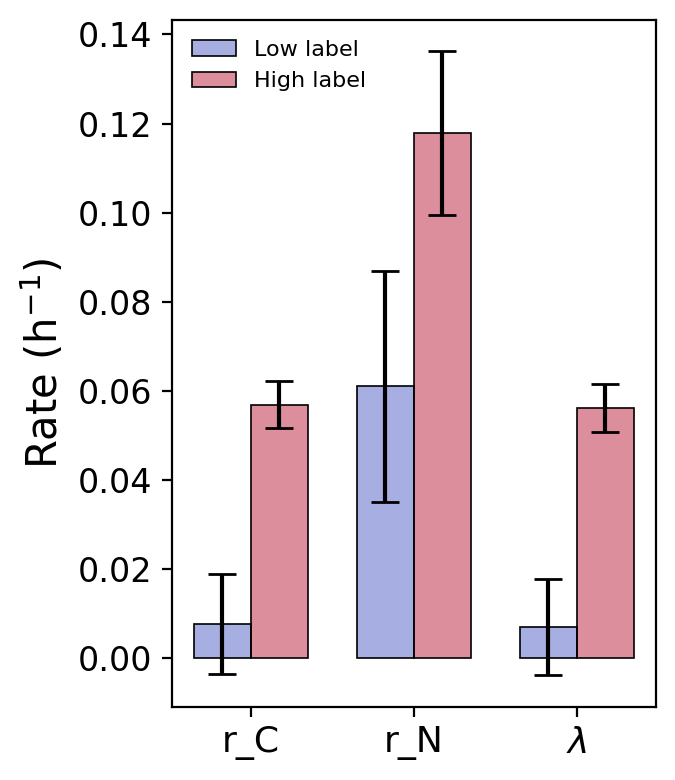

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- Load data ---
df2 = pd.read_csv(
    'results_new/results_std_corrected_12h_PEAKS.dat',
    sep='\t'
)
clusters = pd.read_csv('results_new/clusters_4to12h_N_NEW.dat', sep='\t')

# attach cluster labels to df2 -- assumes same row order/length as clusters
df2 = df2.reset_index(drop=True)
df2['cluster'] = clusters['cluster'].values

# --- Colors: same coolwarm extremes used in the scatter/histogram figures ---
cmap = plt.cm.coolwarm
color_peak1 = cmap(0.0)[:3] + (0.45,)   # Peak 1 (cluster 0)
color_peak2 = cmap(1.0)[:3] + (0.45,)   # Peak 2 (cluster 1)
PEAK_COLORS = {0: color_peak1, 1: color_peak2}
PEAK_LABELS = {0: "Low label", 1: "High label"}

# =========================
# Compute statistics per cluster
# =========================
variables = ['r_C', 'r_N', 'g']
labels = ['r_C', 'r_N', r'$\lambda$']

stats = {}  # cluster_id -> (means, sds)
for cluster_id in sorted(df2['cluster'].unique()):
    sub = df2[df2['cluster'] == cluster_id]
    stats[cluster_id] = (
        [np.mean(sub[v]) for v in variables],
        [np.std(sub[v]) for v in variables],
    )

# =========================
# Plot
# =========================
x = np.arange(len(labels))
cluster_ids = sorted(df2['cluster'].unique())
n_clusters = len(cluster_ids)
bar_width = 0.7 / n_clusters

plt.rcParams['figure.figsize'] = [4/1.15, 4/1.0]
fig, ax = plt.subplots()

for i, cluster_id in enumerate(cluster_ids):
    offset = (i - (n_clusters - 1) / 2) * bar_width
    means, sds = stats[cluster_id]
    ax.bar(
        x + offset, means, bar_width, yerr=sds,
        label=PEAK_LABELS[cluster_id],
        color=PEAK_COLORS[cluster_id],
        edgecolor='black', linewidth=0.6, capsize=5,
    )

# =========================
# Formatting
# =========================
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=13)
ax.set_ylabel(r'Rate (h$^{-1}$)', fontsize=15)
ax.tick_params(axis='y', labelsize=12)
ax.legend(fontsize=8, frameon=False, loc='upper left')
plt.tight_layout()

# =========================
# Save
# =========================
plt.savefig(
    'turnover_barplot_grouped.svg',
    format='svg',
    dpi=2000
)
plt.savefig(
    '../../drafts/synecho/def_figures/turnover_barplot_grouped.eps',
    format='eps'
)
plt.show()